In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder,OrdinalEncoder,PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import clone


In [102]:
df = pd.read_csv("car_details.csv")

In [103]:
df.shape

(2059, 20)

In [104]:
df.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [105]:
df.describe()

,Price,Year,Kilometer,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
count,2.059000e+03,2059.000000,2.059000e+03,1995.000000,1995.000000,1995.000000,1995.000000,1946.000000
mean,1.702992e+06,2016.425449,5.422471e+04,4280.860652,1767.991980,1591.735338,5.306266,52.002210
std,2.419881e+06,3.363564,5.736172e+04,442.458507,135.265825,136.073956,0.822170,15.110198
min,4.900000e+04,1988.000000,0.000000e+00,3099.000000,1475.000000,1165.000000,2.000000,15.000000
25%,4.849990e+05,2014.000000,2.900000e+04,3985.000000,1695.000000,1485.000000,5.000000,41.250000
50%,8.250000e+05,2017.000000,5.000000e+04,4370.000000,1770.000000,1545.000000,5.000000,50.000000
75%,1.925000e+06,2019.000000,7.200000e+04,4629.000000,1831.500000,1675.000000,5.000000,60.000000
max,3.500000e+07,2022.000000,2.000000e+06,5569.000000,2220.000000,1995.000000,8.000000,105.000000


In [106]:
df.describe(include="object")
# Label encoding for Owner column only, OneHot for all other categorical columns.
# Impute Engine Max Power, Max Torque into Numerical columns.

C:\Users\PC\AppData\Local\Temp\ipykernel_8528\1460209260.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Make,Model,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain
count,2059,2059,2059,2059,2059,2059,2059,2059,1979,1979,1979,1923
unique,33,1050,9,2,77,17,6,3,108,335,290,3
top,Maruti Suzuki,X1 sDrive20d xLine,Diesel,Manual,Mumbai,White,First,Individual,1197 cc,89 bhp @ 4000 rpm,200 Nm @ 1750 rpm,FWD
freq,440,15,1049,1133,342,802,1619,1997,231,90,90,1330


In [107]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   str    
 1   Model               2059 non-null   str    
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   str    
 6   Transmission        2059 non-null   str    
 7   Location            2059 non-null   str    
 8   Color               2059 non-null   str    
 9   Owner               2059 non-null   str    
 10  Seller Type         2059 non-null   str    
 11  Engine              1979 non-null   str    
 12  Max Power           1979 non-null   str    
 13  Max Torque          1979 non-null   str    
 14  Drivetrain          1923 non-null   str    
 15  Length              1995 non-null   float64
 16  Width            

In [108]:
df.isnull().sum()

Make                    0
Model                   0
Price                   0
Year                    0
Kilometer               0
Fuel Type               0
Transmission            0
Location                0
Color                   0
Owner                   0
Seller Type             0
Engine                 80
Max Power              80
Max Torque             80
Drivetrain            136
Length                 64
Width                  64
Height                 64
Seating Capacity       64
Fuel Tank Capacity    113
dtype: int64

In [109]:
df.dtypes

Make                      str
Model                     str
Price                   int64
Year                    int64
Kilometer               int64
Fuel Type                 str
Transmission              str
Location                  str
Color                     str
Owner                     str
Seller Type               str
Engine                    str
Max Power                 str
Max Torque                str
Drivetrain                str
Length                float64
Width                 float64
Height                float64
Seating Capacity      float64
Fuel Tank Capacity    float64
dtype: object

In [110]:
X = df.drop(columns=["Price"])
y = df["Price"]

In [111]:
numerical_Features = X.select_dtypes(include = "number").columns.to_list()
numerical_Features

['Year',
 'Kilometer',
 'Length',
 'Width',
 'Height',
 'Seating Capacity',
 'Fuel Tank Capacity']

In [112]:
Categorical_Features = X.select_dtypes(include = "object").columns.to_list()
Categorical_Features

C:\Users\PC\AppData\Local\Temp\ipykernel_8528\880275117.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Categorical_Features = X.select_dtypes(include = "object").columns.to_list()


['Make',
 'Model',
 'Fuel Type',
 'Transmission',
 'Location',
 'Color',
 'Owner',
 'Seller Type',
 'Engine',
 'Max Power',
 'Max Torque',
 'Drivetrain']

Here 'Engine', 'Max Power', 'Max Toque' are stored in string but should be in stored numerical dtype.

In [113]:
df["Engine Size(cc)"] = df["Engine"].str.split(" cc").str[0].astype(float)
df.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,...,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,Engine Size(cc)
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,...,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0,1198.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,...,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0,1248.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,...,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0,1197.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,...,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0,1197.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,...,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0,2393.0


In [114]:
X["Max Power"].value_counts()

Max Power
89 bhp @ 4000 rpm     90
82 bhp @ 6000 rpm     62
126 bhp @ 4000 rpm    55
83 bhp @ 6000 rpm     55
74 bhp @ 4000 rpm     50
                      ..
198@4000               1
247 bhp @ 5500 rpm     1
197 bhp @ 5000 rpm     1
70 bhp @ 4000 rpm      1
329 bhp @ 5250 rpm     1
Name: count, Length: 335, dtype: int64

In [115]:
X["Max Power(BHP)"] = pd.to_numeric(
    X["Max Power"].str.split(" ").str[0].str.replace("bhp", "", case=False),
    errors="coerce")

X["Max Power(rpm)"] = pd.to_numeric(
    X["Max Power"].str.split("@").str[1].str.replace("rpm", "", case=False),
    errors="coerce")

X["Max Torque(Nm)"] = pd.to_numeric(
    X["Max Torque"].str.split(" ").str[0].str.replace("Nm", "", case=False),
    errors="coerce")

X["Max Torque(rpm)"] = pd.to_numeric(
    X["Max Torque"].str.split("@").str[1].str.replace("rpm", "", case=False),
    errors="coerce")

X.shape

(2059, 23)

In [116]:
X.drop(columns = ["Engine", "Max Power", "Max Torque"], inplace = True)
X.shape

(2059, 20)

In [117]:
numerical_Features = X.select_dtypes(include = "number").columns.to_list()
numerical_Features

['Year',
 'Kilometer',
 'Length',
 'Width',
 'Height',
 'Seating Capacity',
 'Fuel Tank Capacity',
 'Max Power(BHP)',
 'Max Power(rpm)',
 'Max Torque(Nm)',
 'Max Torque(rpm)']

In [118]:
X["Transmission"].value_counts()

Transmission
Manual       1133
Automatic     926
Name: count, dtype: int64

In [119]:
Ordinal_Features = ["Owner"]
Nominal_Features = X.select_dtypes(include = "object").columns.to_list()
Nominal_Features.remove("Owner")
Nominal_Features

C:\Users\PC\AppData\Local\Temp\ipykernel_8528\4113685734.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Nominal_Features = X.select_dtypes(include = "object").columns.to_list()


['Make',
 'Model',
 'Fuel Type',
 'Transmission',
 'Location',
 'Color',
 'Seller Type',
 'Drivetrain']

In [120]:
numerical_columns = df.select_dtypes(include = "number").columns.to_list()
for feature in numerical_columns:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lowerBound = Q1 - 1.5*IQR
    upperBound = Q3 + 1.5*IQR
    outLiers = df[(df[feature]<lowerBound) | (df[feature]>upperBound)]
    print("'",feature,"':")
    print("\tLower Bound:", lowerBound)
    print("\tUpper Bound:", upperBound,"\n")


' Price ':
	Lower Bound: -1675002.5
	Upper Bound: 4085001.5 

' Year ':
	Lower Bound: 2006.5
	Upper Bound: 2026.5 

' Kilometer ':
	Lower Bound: -35500.0
	Upper Bound: 136500.0 

' Length ':
	Lower Bound: 3019.0
	Upper Bound: 5595.0 

' Width ':
	Lower Bound: 1490.25
	Upper Bound: 2036.25 

' Height ':
	Lower Bound: 1200.0
	Upper Bound: 1960.0 

' Seating Capacity ':
	Lower Bound: 5.0
	Upper Bound: 5.0 

' Fuel Tank Capacity ':
	Lower Bound: 13.125
	Upper Bound: 88.125 

' Engine Size(cc) ':
	Lower Bound: 0.0
	Upper Bound: 3192.0 



In [121]:
df.isnull().sum()

Make                    0
Model                   0
Price                   0
Year                    0
Kilometer               0
Fuel Type               0
Transmission            0
Location                0
Color                   0
Owner                   0
Seller Type             0
Engine                 80
Max Power              80
Max Torque             80
Drivetrain            136
Length                 64
Width                  64
Height                 64
Seating Capacity       64
Fuel Tank Capacity    113
Engine Size(cc)        80
dtype: int64

In [122]:
#check for any -ve values
for col in numerical_columns:
    print(col)
    print(df[df[col]<0],"\n\n")

Price
Empty DataFrame
Columns: [Make, Model, Price, Year, Kilometer, Fuel Type, Transmission, Location, Color, Owner, Seller Type, Engine, Max Power, Max Torque, Drivetrain, Length, Width, Height, Seating Capacity, Fuel Tank Capacity, Engine Size(cc)]
Index: []

[0 rows x 21 columns] 


Year
Empty DataFrame
Columns: [Make, Model, Price, Year, Kilometer, Fuel Type, Transmission, Location, Color, Owner, Seller Type, Engine, Max Power, Max Torque, Drivetrain, Length, Width, Height, Seating Capacity, Fuel Tank Capacity, Engine Size(cc)]
Index: []

[0 rows x 21 columns] 


Kilometer
Empty DataFrame
Columns: [Make, Model, Price, Year, Kilometer, Fuel Type, Transmission, Location, Color, Owner, Seller Type, Engine, Max Power, Max Torque, Drivetrain, Length, Width, Height, Seating Capacity, Fuel Tank Capacity, Engine Size(cc)]
Index: []

[0 rows x 21 columns] 


Length
Empty DataFrame
Columns: [Make, Model, Price, Year, Kilometer, Fuel Type, Transmission, Location, Color, Owner, Seller Type, E

In [123]:
df_outliers = df[df["Price"] > 4085001.5]
df_outliers["Price"].nunique()

df_outliers["Price"].nunique()

115

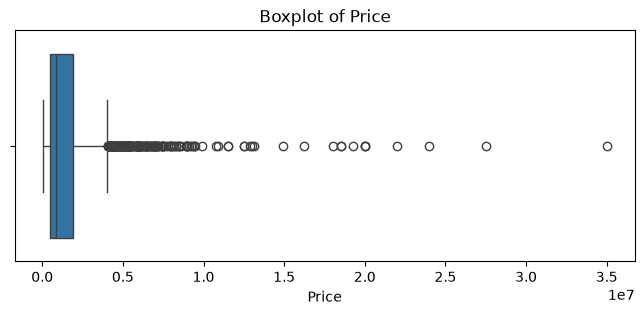

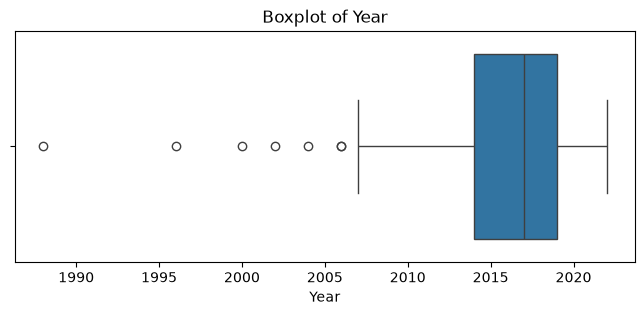

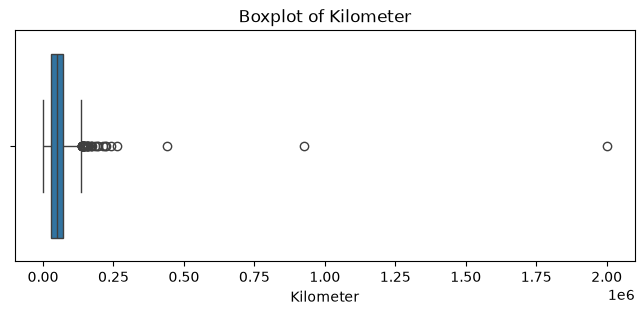

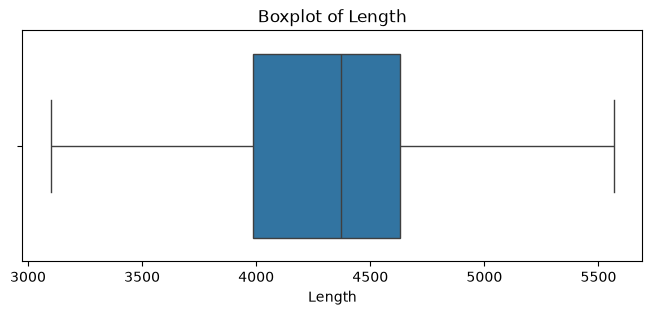

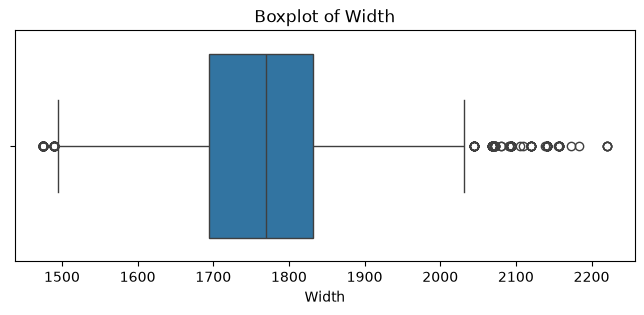

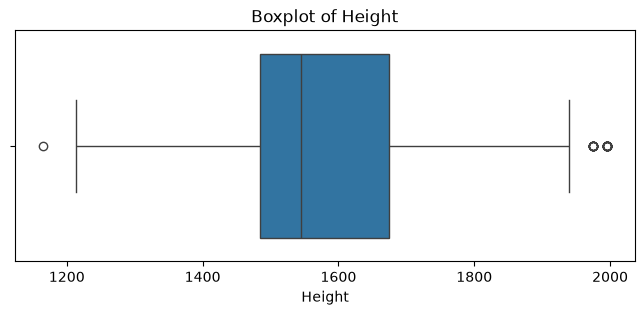

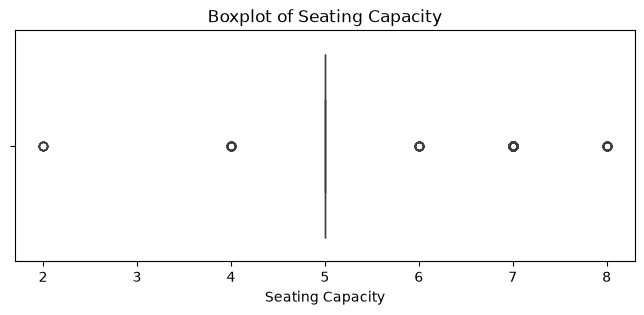

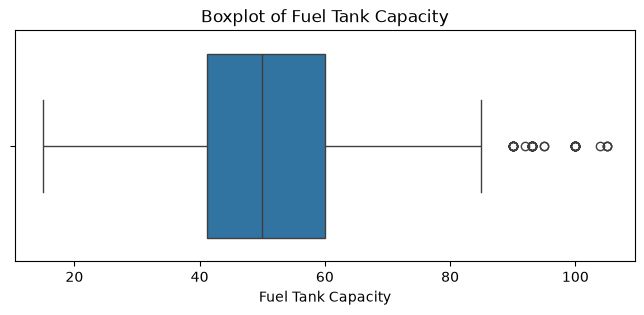

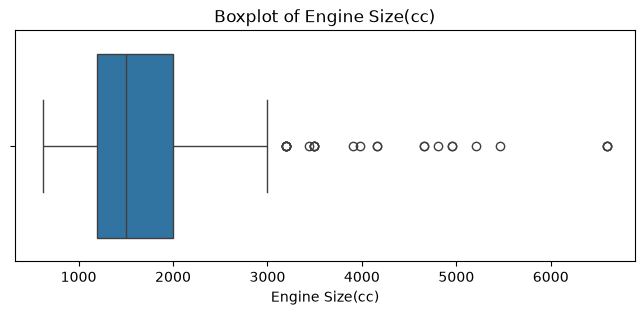

In [124]:
for feature in numerical_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.show()

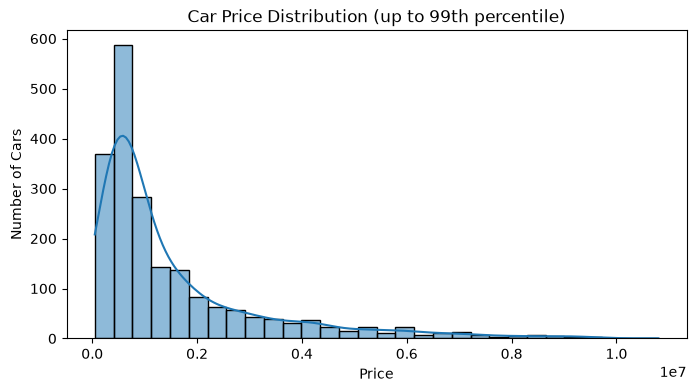

In [125]:
# 1. Price distribution (hide extreme top 1% only in the graph)
plt.figure(figsize=(8, 4))
sns.histplot(df.loc[df["Price"] <= df["Price"].quantile(0.99), "Price"], bins=30, kde=True)
plt.title("Car Price Distribution (up to 99th percentile)")
plt.xlabel("Price")
plt.ylabel("Number of Cars")
plt.show()

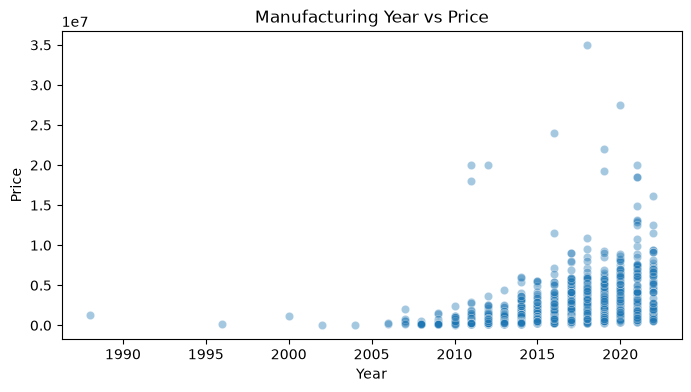

In [126]:
# 2. Year vs Price
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="Year", y="Price", alpha=0.4)
plt.title("Manufacturing Year vs Price")
plt.show()

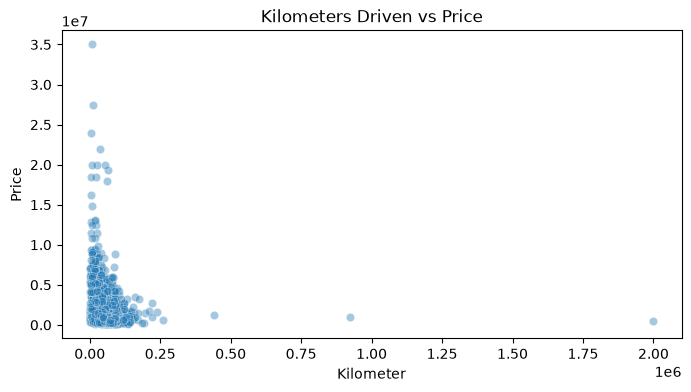

In [127]:
# 3. Kilometer vs Price
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="Kilometer", y="Price", alpha=0.4)
plt.title("Kilometers Driven vs Price")
plt.show()

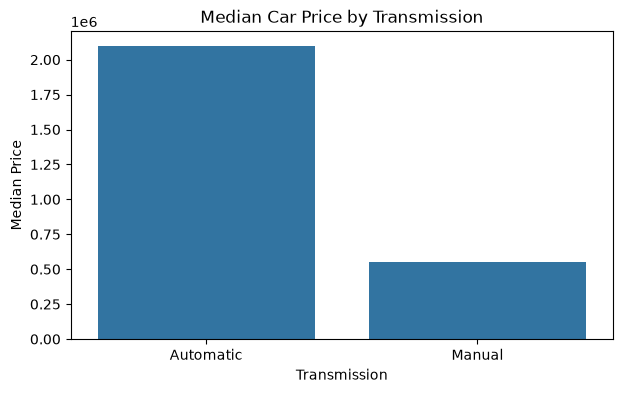

In [128]:
# 4. Median price by transmission type
median_prices = df.groupby("Transmission")["Price"].median()
plt.figure(figsize=(7, 4))
sns.barplot(x=median_prices.index, y=median_prices.values)
plt.title("Median Car Price by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Median Price")

plt.show()

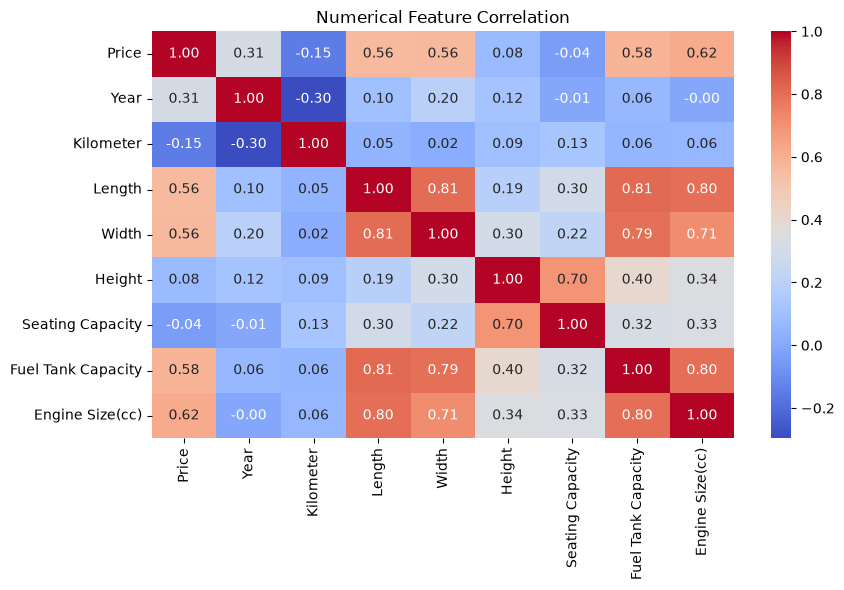

In [129]:
# 5. Correlation between numerical features
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Feature Correlation")
plt.tight_layout()
plt.show()

# Imputation:

In [130]:
Numerica_Pipeline = Pipeline([
    ("Imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


Ordinal_Pipeline = Pipeline([
    ("Imputer", SimpleImputer(strategy="most_frequent")),
    ("OrdinalEncoder", OrdinalEncoder(
        categories=[[
            "First",
            "Second",
            "Third",
            "Fourth",
            "4 or More",
            "UnRegistered Car"
        ]],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

Nominal_Pipeline = Pipeline([
    ("Imputer", SimpleImputer(strategy="most_frequent")),
    ("OneHotEncoder", OneHotEncoder(handle_unknown="ignore"))
])


Polynomial_Numerical_Pipeline = Pipeline([
    ("Imputer", SimpleImputer(strategy="median")),
    ("Polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("Scaler", StandardScaler())
])

In [131]:
Transformer = ColumnTransformer([
    ("Numerical", Numerica_Pipeline, numerical_Features),
    ("Ordinal", Ordinal_Pipeline, Ordinal_Features),
    ("Nominal", Nominal_Pipeline, Nominal_Features)
])

Polynomial_Transformer = ColumnTransformer([
    ("Numerical", Polynomial_Numerical_Pipeline,
     numerical_Features),

    ("Ordinal", clone(Ordinal_Pipeline),
     Ordinal_Features),

    ("Nominal", clone(Nominal_Pipeline),
     Nominal_Features)
])



# Models:

In [132]:
Linear_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", LinearRegression())
])

RandomForest_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", RandomForestRegressor())
])

Ridge_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", Ridge())
])

Lasso_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", Lasso())
])

ElasticNet_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", ElasticNet())
]) 

SGD_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", SGDRegressor())
])

GradientBoosting_Model = Pipeline([
    ("Transformer", clone(Transformer)),
    ("Regressor", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

Polynomial_Model = Pipeline([
    ("Transformer", Polynomial_Transformer),
    ("Regressor", LinearRegression())
])


# Train Test Split

In [133]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Training + Prediction

In [134]:
Linear_Model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Make','Model','Year',...,'Max Power(rpm)','Max Torque(Nm)', 'Max Torque(rpm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [135]:
y_predict = Linear_Model.predict(X_test)

print("Linear Regression Model Performance:\n")
print("Trainning Score:", Linear_Model.score(X_train, y_train))
print("Testing Score:", Linear_Model.score(X_test, y_test))
Lin_mse = mean_squared_error(y_test, y_predict)
Lin_rmse = np.sqrt(Lin_mse)
Lin_r2 = r2_score(y_test, y_predict)
print(f"\n\nMean Squared Error: {Lin_mse}")
print(f"Root Mean Squared Error: {Lin_rmse}")
print(f"R-squared: {Lin_r2}")

Linear Regression Model Performance:

Trainning Score: 0.9925431153275097
Testing Score: 0.07809244463634446


Mean Squared Error: 6440706334088.917
Root Mean Squared Error: 2537854.6715856125
R-squared: 0.07809244463634446


In [136]:
RandomForest_Model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Make','Model','Year',...,'Max Power(rpm)','Max Torque(Nm)', 'Max Torque(rpm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [137]:
y_predict = RandomForest_Model.predict(X_test)
print("Random Forest Model Performance:\n")
print("Trainning Score:", RandomForest_Model.score(X_train, y_train))
print("Testing Score:", RandomForest_Model.score(X_test, y_test))
RandFor_mse = mean_squared_error(y_test, y_predict)
RandFor_rmse = np.sqrt(RandFor_mse)
RandFor_r2 = r2_score(y_test, y_predict)
print(f"\n\nMean Squared Error: {RandFor_mse}")
print(f"Root Mean Squared Error: {RandFor_rmse}")
print(f"R-squared: {RandFor_r2}")


Random Forest Model Performance:

Trainning Score: 0.9802537322832191
Testing Score: 0.8194821902427097


Mean Squared Error: 1261148359133.486
Root Mean Squared Error: 1123008.619349596
R-squared: 0.8194821902427097


In [138]:
Ridge_Model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Make','Model','Year',...,'Max Power(rpm)','Max Torque(Nm)', 'Max Torque(rpm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [139]:
y_predict = Ridge_Model.predict(X_test)
print("Ridge Regression Model Performance:\n")
print("Trainning Score:", Ridge_Model.score(X_train, y_train))
print("Testing Score:", Ridge_Model.score(X_test, y_test))
Ridge_mse = mean_squared_error(y_test, y_predict)
Ridge_rmse = np.sqrt(Ridge_mse)
Ridge_r2 = r2_score(y_test, y_predict)
print(f"\n\nMean Squared Error: {Ridge_mse}")
print(f"Root Mean Squared Error: {Ridge_rmse}")
print(f"R-squared: {Ridge_r2}")

Ridge Regression Model Performance:

Trainning Score: 0.9476180684065187
Testing Score: 0.7526252265811071


Mean Squared Error: 1728229973583.8416
Root Mean Squared Error: 1314621.6085185278
R-squared: 0.7526252265811071


In [140]:
Lasso_Model.fit(X_train, y_train)

c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.674986e+13, tolerance: 9.173e+11
  model = cd_fast.sparse_enet_coordinate_descent(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Make','Model','Year',...,'Max Power(rpm)','Max Torque(Nm)', 'Max Torque(rpm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [141]:
y_predict = Lasso_Model.predict(X_test)
print("Lasso Regression Model Performance:\n")
print("Trainning Score:", Lasso_Model.score(X_train, y_train))
print("Testing Score:", Lasso_Model.score(X_test, y_test))
Lasso_mse = mean_squared_error(y_test, y_predict)
Lasso_rmse = np.sqrt(Lasso_mse)
Lasso_r2 = r2_score(y_test, y_predict)
print(f"\n\nMean Squared Error: {Lasso_mse}")
print(f"Root Mean Squared Error: {Lasso_rmse}")
print(f"R-squared: {Lasso_r2}")

Lasso Regression Model Performance:

Trainning Score: 0.9922630379439392
Testing Score: 0.5606238556369987


Mean Squared Error: 3069605731704.921
Root Mean Squared Error: 1752029.0327802564
R-squared: 0.5606238556369987


In [142]:
ElasticNet_Model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Make','Model','Year',...,'Max Power(rpm)','Max Torque(Nm)', 'Max Torque(rpm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [143]:
y_predict = ElasticNet_Model.predict(X_test)
print("Elastic Net Regression Model Performance:\n")
print("Trainning Score:", ElasticNet_Model.score(X_train, y_train))
print("Testing Score:", ElasticNet_Model.score(X_test, y_test))
Elastic_mse = mean_squared_error(y_test, y_predict)
Elastic_rmse = np.sqrt(Elastic_mse)
Elastic_r2 = r2_score(y_test, y_predict)
print(f"\n\nMean Squared Error: {Elastic_mse}")
print(f"Root Mean Squared Error: {Elastic_rmse}")
print(f"R-squared: {Elastic_r2}")

Elastic Net Regression Model Performance:

Trainning Score: 0.6343512210633875
Testing Score: 0.6005234778782613


Mean Squared Error: 2790855711486.5854
Root Mean Squared Error: 1670585.4397445782
R-squared: 0.6005234778782613


In [144]:
SGD_Model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Make','Model','Year',...,'Max Power(rpm)','Max Torque(Nm)', 'Max Torque(rpm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [145]:
y_predict = SGD_Model.predict(X_test)
print("SGD Regression Model Performance:\n")
print("Trainning Score:", SGD_Model.score(X_train, y_train))
print("Testing Score:", SGD_Model.score(X_test, y_test))
SGD_mse = mean_squared_error(y_test, y_predict)
SGD_rmse = np.sqrt(SGD_mse)
SGD_r2 = r2_score(y_test, y_predict)
print(f"\n\nMean Squared Error: {SGD_mse}")
print(f"Root Mean Squared Error: {SGD_rmse}")
print(f"R-squared: {SGD_r2}")

SGD Regression Model Performance:

Trainning Score: 0.8099144881089226
Testing Score: 0.747643219186001


Mean Squared Error: 1763035683114.533
Root Mean Squared Error: 1327793.5393405606
R-squared: 0.747643219186001


In [146]:
Polynomial_Model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Make','Model','Year',...,'Max Power(rpm)','Max Torque(Nm)', 'Max Torque(rpm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [147]:
y_predict= Polynomial_Model.predict(X_test)
print("Polynomial Regression Model Performance:\n")
print("\n\nTrainning Score:", Polynomial_Model.score(X_train, y_train))
print("Testing Score:", Polynomial_Model.score(X_test, y_test)) 
Poly_mse = mean_squared_error(y_test, y_predict)
Poly_rmse = np.sqrt(Poly_mse)
Poly_r2 = r2_score(y_test, y_predict)
print(f"\n\nMean Squared Error: {Poly_mse}")
print(f"Root Mean Squared Error: {Poly_rmse}")
print(f"R-squared: {Poly_r2}")

Polynomial Regression Model Performance:



Trainning Score: 0.996515291617304
Testing Score: 0.7728435773202873


Mean Squared Error: 1586978869920.5217
Root Mean Squared Error: 1259753.495696885
R-squared: 0.7728435773202873


In [148]:
GradientBoosting_Model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Make','Model','Year',...,'Max Power(rpm)','Max Torque(Nm)', 'Max Torque(rpm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

In [149]:
y_predict = GradientBoosting_Model.predict(X_test)
print("Gradient Boosting Regression Model Performance:\n")
print("\n\nTrainning Score:", GradientBoosting_Model.score(X_train, y_train))
print("Testing Score:", GradientBoosting_Model.score(X_test, y_test))
GB_mse = mean_squared_error(y_test, y_predict)
GB_rmse = np.sqrt(GB_mse)
GB_r2 = r2_score(y_test, y_predict)
print(f"\n\nMean Squared Error: {GB_mse}")
print(f"Root Mean Squared Error: {GB_rmse}")
print(f"R-squared: {GB_r2}")

Gradient Boosting Regression Model Performance:



Trainning Score: 0.9749121264703955
Testing Score: 0.868461502164283


Mean Squared Error: 918965064618.4988
Root Mean Squared Error: 958626.655491333
R-squared: 0.868461502164283


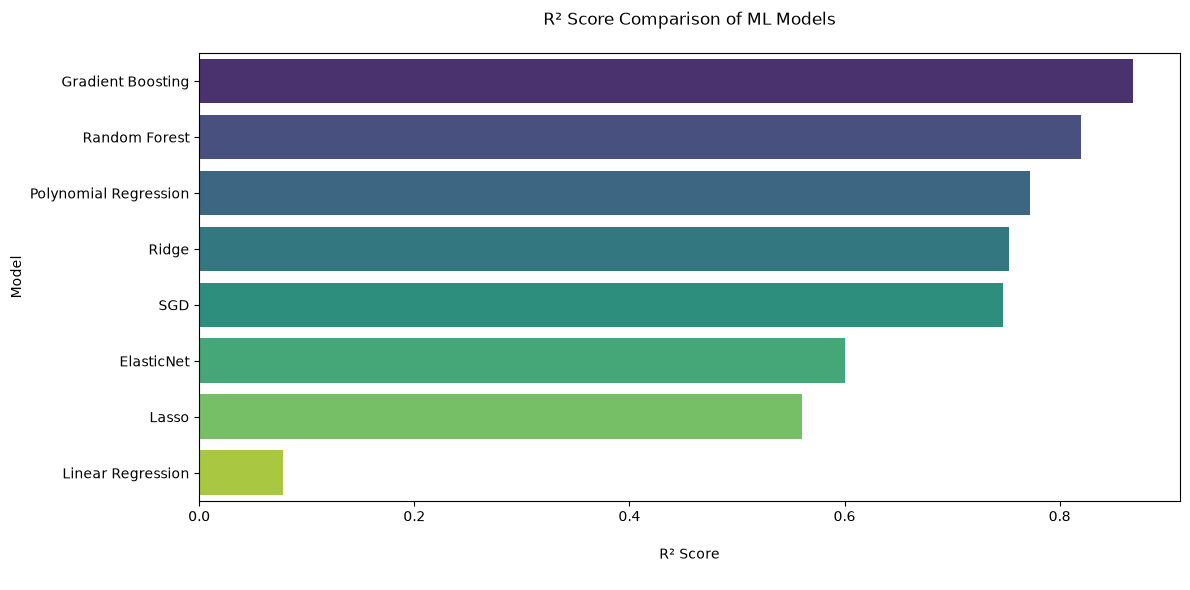

In [169]:

r2_results = {
    "Linear Regression": Lin_r2,
    "Gradient Boosting": GB_r2,
    "Polynomial Regression": Poly_r2,
    "SGD": SGD_r2,
    "Lasso": Lasso_r2,
    "Ridge": Ridge_r2,
    "Random Forest": RandFor_r2,
    "ElasticNet": Elastic_r2
}

df_r2 = pd.DataFrame(
    r2_results.items(),
    columns=["Model", "R2 Score"]
)

df_r2 = df_r2.sort_values("R2 Score", ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_r2,
    y="Model",
    x="R2 Score",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.xticks(rotation = 0, ha="center")
plt.title("R² Score Comparison of ML Models\n")
plt.xlabel("\nR² Score\n")
plt.tight_layout()
plt.show()